In [1]:
#Import the necessary Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
#Load and explore the dataset then display first few rolws
# Load Wine Dataset
wine = load_wine()

# Convert to DataFrame
df = pd.DataFrame(wine.data, columns=wine.feature_names)

# Add target variable
df["target"] = wine.target

# Display first five rows
print("First 5 rows:")
display(df.head())

# Display dataset shape
print("Dataset Shape:", df.shape)

# Display wine classes
print("Wine Classes:", wine.target_names)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

First 5 rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


Dataset Shape: (178, 14)
Wine Classes: ['class_0' 'class_1' 'class_2']
Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [3]:
#Split the dataset into 80% training and 20% testing set
# Define features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set:", X_test.shape)

Training Set: (142, 13)
Testing Set: (36, 13)


**Build a Decision Tree Classifier**

In [5]:
# Initialize Decision Tree Classifier using gini
dt_classifier = DecisionTreeClassifier(
    criterion="gini", # this criterion tells the algorithm to use gini to selct the best feature and thrshehold for spliting the data.
    random_state=42
)

# Train model
dt_classifier.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


**Make Predictions**

In [6]:
# Predict wine classes
y_pred = dt_classifier.predict(X_test)

# Compare actual and predicted values
results = pd.DataFrame({
    "Actual Wine Type": y_test.values,
    "Predicted Wine Type": y_pred
})

display(results.head(10))

,Actual Wine Type,Predicted Wine Type
0,0,0
1,2,1
2,0,0
3,1,1
4,1,1
5,0,0
6,0,0
7,1,1
8,1,1
9,2,2


**Evaluate the Model**

In [9]:
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Decision Tree Accuracy: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

Decision Tree Accuracy: 0.9444
Accuracy Percentage: 94.44%


Note that accuracy measures the proportion of correctly classified wine samples. The model archived 94.44 % of accuracy. meaning that the model correctly determine  the right wine sample 94.44% of the times.

Confusion Matrix:
[[11  1  0]
 [ 0 14  0]
 [ 0  1  9]]


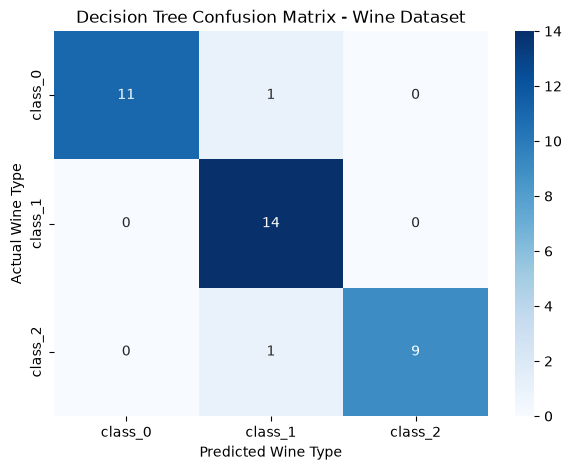

In [10]:
#Visualize the confusion matrix
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=wine.target_names,
    yticklabels=wine.target_names
)

plt.title("Decision Tree Confusion Matrix - Wine Dataset")
plt.xlabel("Predicted Wine Type")
plt.ylabel("Actual Wine Type")
plt.show()

Note that the leading diagona correctly classifies wine classes. Therefore, of the 36 test samples, the model correctly predict 34 (11+14+9). 

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36



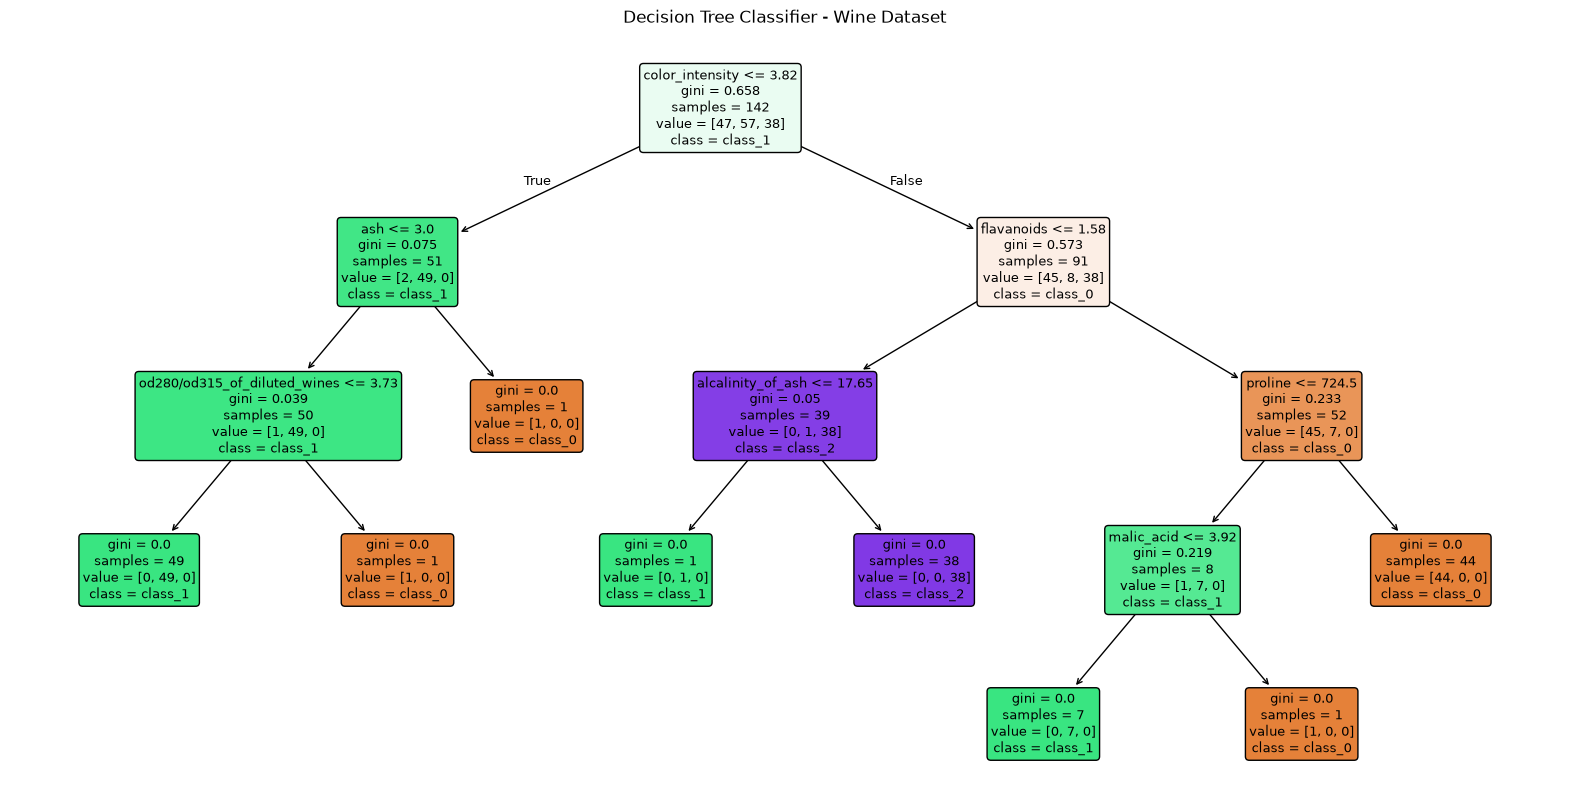

In [11]:
#Plot the decision tree using plot_tree().
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred,
    target_names=wine.target_names
))


plt.figure(figsize=(20, 10))

plot_tree(
    dt_classifier,
    feature_names=wine.feature_names,
    class_names=wine.target_names,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Decision Tree Classifier - Wine Dataset")
plt.show()


In [12]:
#Improve the decision Tree model using hyperparameter
# Train an optimized Decision Tree
dt_optimized = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)

dt_optimized.fit(X_train, y_train)

# Make predictions
y_pred_optimized = dt_optimized.predict(X_test)

# Compare performance
comparison = pd.DataFrame({
    "Model": ["Original Decision Tree", "Optimized Decision Tree"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_optimized)
    ]
})

display(comparison)

,Model,Accuracy
0,Original Decision Tree,0.944444
1,Optimized Decision Tree,1.000000


Optimizing teh model has led to 100% accuracy. This is because the optimized tree limits its depth and uses minimum number of samples before splitting. These helps to reduce overfitting and improve generalization.

**Initialize the model using Entropy**

In [13]:
dt_classifierN = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

# Train model
dt_classifierN.fit(X_train, y_train)

print("Decision Tree trained successfully using Entropy!")

Decision Tree trained successfully using Entropy!


In [14]:
# Make predictions
y_predN = dt_classifierN.predict(X_test)

# Calculate accuracy
accuracyN = accuracy_score(y_test, y_predN)

print(f"Entropy Decision Tree Accuracy: {accuracyN * 100:.2f}%")

# Confusion Matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_predN))

Entropy Decision Tree Accuracy: 97.22%
Confusion Matrix:
[[12  0  0]
 [ 0 14  0]
 [ 0  1  9]]


**Compare Gini and Entropy Accuracy**

In [15]:
comparison = pd.DataFrame({
    "Criterion": ["Gini", "Entropy"],
    "Accuracy": [
        accuracy_score(y_test, dt_classifier.predict(X_test)),
        accuracy_score(y_test, dt_classifierN.predict(X_test))
    ]
})

display(comparison)

,Criterion,Accuracy
0,Gini,0.944444
1,Entropy,0.972222


Even though the hyperparameter(optimized) model already achive 100% accuracy, I wanted to see how different it is using Entropy and GINI. nd based on the result, Entropy acihieved a high accuracy than Gini for this dataset

**Decision Tree for Regression using the Linnerud dataset**

The Linnerud Dataset contains information about 20 middle-aged men who participated in a physical fitness study. It has three input features as follows:
Chins: Number of chin-ups performed
Situps:Number of sit-ups performed
Jumps: Number of jumping exercises performed

It has three targets feasures as follows:
Weight, Waist, and Pulse.

The goal of the decision tree model is to use the number of chin-ups, sit-ups, and jumps performed by an individual to estimate their weight, waist measurement, and pulse rate.

In [16]:
import numpy as np
import matplotlib.pyplot as plt


from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, r2_score

In [17]:
# Load dataset
linnerud = load_linnerud()

# Create input features DataFrame
X = pd.DataFrame(
    linnerud.data,
    columns=linnerud.feature_names
)

# Create target DataFrame
y = pd.DataFrame(
    linnerud.target,
    columns=linnerud.target_names
)

# Combine features and targets
df = pd.concat([X, y], axis=1)

# Display first five rows
print("First 5 rows:")
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)

print("\nInput Features:", linnerud.feature_names)
print("Target Variables:", linnerud.target_names)

# Summary statistics
display(df.describe())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

First 5 rows:


,Chins,Situps,Jumps,Weight,Waist,Pulse
0,5.0,162.0,60.0,191.0,36.0,50.0
1,2.0,110.0,60.0,189.0,37.0,52.0
2,12.0,101.0,101.0,193.0,38.0,58.0
3,12.0,105.0,37.0,162.0,35.0,62.0
4,13.0,155.0,58.0,189.0,35.0,46.0


Dataset Shape: (20, 6)

Input Features: ['Chins', 'Situps', 'Jumps']
Target Variables: ['Weight', 'Waist', 'Pulse']


,Chins,Situps,Jumps,Weight,Waist,Pulse
count,20.000000,20.000000,20.00000,20.000000,20.000000,20.000000
mean,9.450000,145.550000,70.30000,178.600000,35.400000,56.100000
std,5.286278,62.566575,51.27747,24.690505,3.201973,7.210373
min,1.000000,50.000000,25.00000,138.000000,31.000000,46.000000
25%,4.750000,101.000000,39.50000,160.750000,33.000000,51.500000
50%,11.500000,122.500000,54.00000,176.000000,35.000000,55.000000
75%,13.250000,210.000000,85.25000,191.500000,37.000000,60.500000
max,17.000000,251.000000,250.00000,247.000000,46.000000,74.000000



Missing Values:
Chins     0
Situps    0
Jumps     0
Weight    0
Waist     0
Pulse     0
dtype: int64


The dataset contains 20 observations and 6 columns: 3 input features and 3 target variables. Each row represents one participant. and there are no missing values.

**Split the data into training (80%) and testing (20%) sets.**

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Targets:", y_train.shape)
print("Testing Targets:", y_test.shape)

Training Features: (16, 3)
Testing Features: (4, 3)
Training Targets: (16, 3)
Testing Targets: (4, 3)


**Build a Decision Tree Regressor**

In [19]:
# Initialize Decision Tree Regressor
dt_regressor = DecisionTreeRegressor(
    criterion="squared_error",
    random_state=42
)

# Train model
dt_regressor.fit(X_train, y_train)

print("Decision Tree Regressor trained successfully!")

Decision Tree Regressor trained successfully!


This model interns to learn how exercise performance relates to weight, waist circumference, and pulse rate.

**Make Predictions**

In [20]:
# Predict target values
y_pred = dt_regressor.predict(X_test)

# Convert predictions to DataFrame
predictions_df = pd.DataFrame(
    y_pred,
    columns=y.columns
)

print("Predicted Values:")
display(predictions_df)

# Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual Weight": y_test["Weight"].values,
    "Predicted Weight": y_pred[:, 0],
    "Actual Waist": y_test["Waist"].values,
    "Predicted Waist": y_pred[:, 1],
    "Actual Pulse": y_test["Pulse"].values,
    "Predicted Pulse": y_pred[:, 2]
})

display(comparison)

Predicted Values:


,Weight,Waist,Pulse
0,189.0,35.0,46.0
1,154.0,34.0,64.0
2,166.0,33.0,52.0
3,138.0,33.0,68.0


,Actual Weight,Predicted Weight,Actual Waist,Predicted Waist,Actual Pulse,Predicted Pulse
0,191.0,189.0,36.0,35.0,50.0,46.0
1,157.0,154.0,32.0,34.0,52.0,64.0
2,202.0,166.0,37.0,33.0,62.0,52.0
3,189.0,138.0,37.0,33.0,52.0,68.0


**Evaluate the Model**

In [21]:
# Calculate metrics for each target
results = []

for i, target in enumerate(y.columns):

    mse = mean_squared_error(
        y_test.iloc[:, i],
        y_pred[:, i]
    )

    r2 = r2_score(
        y_test.iloc[:, i],
        y_pred[:, i]
    )

    results.append({
        "Target": target,
        "MSE": mse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

display(results_df)

,Target,MSE,R2 Score
0,Weight,977.50,-2.476328
1,Waist,9.25,-1.176471
2,Pulse,129.00,-4.863636


Note that the Mean Squared Error (MSE) measures the average squared difference between actual and predicted values. Lower MSE indicates better prediction accuracy and the R² Score measures how well the model predicts the target values compared with simply predicting the test-set mean.

All three R² scores are negative, indicating that the model performs worse than simply predicting the mean of each target in the test set. Overall the Decision Tree Regressor demonstrated poor predictive performance across all three target variables

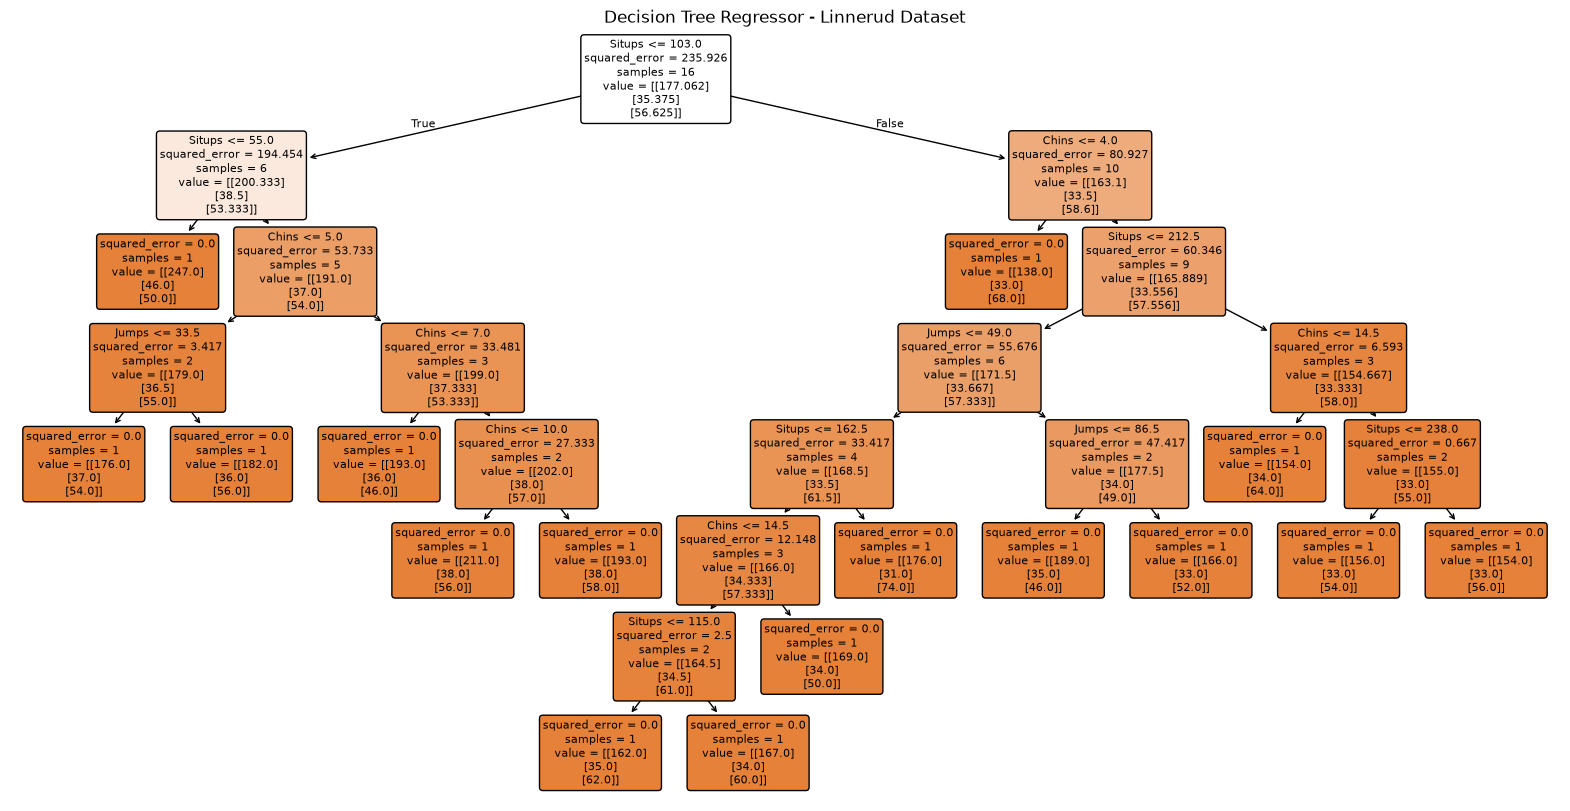

In [22]:
#Visualize the Decision Tree
plt.figure(figsize=(20, 10))

plot_tree(
    dt_regressor,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Regressor - Linnerud Dataset")
plt.show()

The decision tree shows how the model divides participants into groups based on their exercise performance.Each node displays information such as the selected feature, threshold, squared error, number of samples, and predicted target values.

**Visualize the Performance using scatter plots**

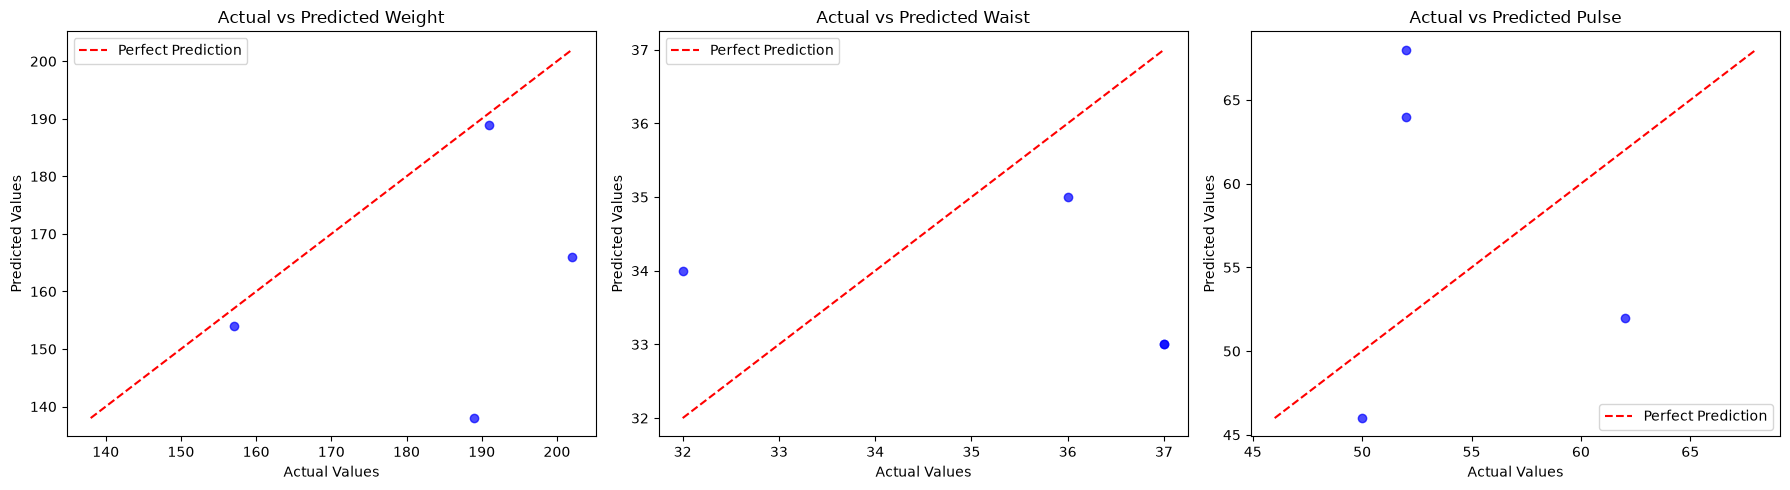

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

targets = y.columns

for i, target in enumerate(targets):

    actual = y_test.iloc[:, i]
    predicted = y_pred[:, i]

    axes[i].scatter(
        actual,
        predicted,
        color="blue",
        alpha=0.7
    )

    # Perfect prediction reference line
    min_val = min(actual.min(), predicted.min())
    max_val = max(actual.max(), predicted.max())

    axes[i].plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--",
        label="Perfect Prediction"
    )

    axes[i].set_xlabel("Actual Values")
    axes[i].set_ylabel("Predicted Values")
    axes[i].set_title(f"Actual vs Predicted {target}")
    axes[i].legend()

plt.tight_layout()
plt.show()

Points closer to the red line indicate better prediction accuracy. The model shows poor performance in predicting weight. Eventhough some points are close to the prediction line, others fall significantly below. Similarly, aits and purse shows very poor performance.

**Use hyperparameter tuning to improve the model**

In [24]:
# Initialize optimized model
dt_optimized = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=3,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

# Train model
dt_optimized.fit(X_train, y_train)

# Make predictions
y_pred_opt = dt_optimized.predict(X_test)

# Compare original and optimized models
comparison_results = []

for name, predictions in [
    ("Original", y_pred),
    ("Optimized", y_pred_opt)
]:
    for i, target in enumerate(y.columns):
        comparison_results.append({
            "Model": name,
            "Target": target,
            "MSE": mean_squared_error(
                y_test.iloc[:, i],
                predictions[:, i]
            ),
            "R2": r2_score(
                y_test.iloc[:, i],
                predictions[:, i]
            )
        })

display(pd.DataFrame(comparison_results))

,Model,Target,MSE,R2
0,Original,Weight,977.500000,-2.476328
1,Original,Waist,9.250000,-1.176471
2,Original,Pulse,129.000000,-4.863636
3,Optimized,Weight,663.541111,-1.359782
4,Optimized,Waist,7.624444,-0.793987
5,Optimized,Pulse,69.330000,-2.151364


The Hyperparameter tuning improved the Decision Tree Regressor's performance across all three target variables. The optimized model reduced MSE by 32.12%(977.50 - 663.54) for Weight, 17.57% for Waist, and 46.26% for Pulse. The R² scores also improved, indicating better predictive performance compared to the original model. However, all R² scores remained negative,